DISCLAIMER: All plotting have been generated with the help of AI tools (Copilot, Claude)

Exercise 2.3

Solve the Korteweg-de Vries (KdV) equation using FFT

$u_t + u_{xxx} - u*u_x = 0$ with initial condition, $u(x,0) = sech(x)$

In [6]:
#Import relevant pacakages
import numpy as np
from scipy.integrate import solve_ivp, odeint
import matplotlib.pyplot as plt


With periodic and smooth functions, it can make sense to use Fourier Transformation to evaluate the derivatives. This is due to Fourier Transformation being based on periodic functions (sin(), cos()). The KdV is smooth and using the chosen initial value, the solution decays to zero quickly, meaning it is periodic in the domain.

The fast Fourier transform (`np.fft`) is used to compute the Fourier coefficients $\hat u_m$ of the grid values, such that $$u(x_j) = \frac1N\sum_m \hat u_m\, e^{i\kappa_m x_j}$$

This is defined on the interval $x\in[-L/2, L/2)$ with $L=200$ and $N=512$ with $x_j = -L/2 + jL/N$ and assumed periodic such that $x_0 = x_N$.

By using the Fourier Transform, the PDE can be transformed to a system of ODE's, which can be solved by ODE's solvers as `solve_ivp`.

Given the chosen domain, $\lambda_m = L/m$, the wavenumbers are found using the `np.fft.fftfreq()` function, which gives the discrete frequencies, $\kappa$.
$$\kappa_m = \frac{2\pi}{\lambda_m} = \frac{2\pi m}{L}.$$
In the code these are `2*np.pi*np.fft.fftfreq(n, d=dx)`.

Differentiating a term $e^{i\kappa x}$ multiplies it by $i\kappa$, so derivatives become multiplications in Fourier space:
$$\widehat{u_x} = i\kappa\,\hat u, \qquad \widehat{u_{xxx}} = (i\kappa)^3\,\hat u$$

Discretizing only in space turns the PDE into a system of ODEs, $\dot{\mathbf u} = F(\mathbf u)$ (the method of lines), which is integrated in time with `scipy.integrate.solve_ivp`. The BDF method is used because the $u_{xxx}$ term makes the system stiff.


In [7]:
L = 200 # domain length
n = 512 # number of evaluations (number of grid points)
dx = L/n # step length
x = np.linspace(-L/2, L/2, n, endpoint=False) # define x domain


kappa = 2*np.pi * np.fft.fftfreq(n, d = dx) # frequencies, discrete ordered wavenumbers

def rhsKdV(t, u, kappa):
    uhat  = np.fft.fft(u)                       # to fourier state for u
    duhat = 1j*kappa * uhat                     # to fourier state for u_x
    ddduhat = np.power((1j * kappa),3) * uhat   # to fourier state for u_xxx
    
    ux = np.fft.ifft(duhat)                     # Back to physical space for u_x
    uxxx = np.fft.ifft(ddduhat)                 # Back to physical space for u_xxx
    return (u*ux - uxxx).real                   # Returns only the real part of the solution

# initial condition
u0 = 1/np.cosh(x) 

T = 50 # Final time
nT = 501 # Number of samples
t = np.linspace(0, T, nT)
t_span = (0,T)
ut = solve_ivp(rhsKdV, t_span, u0, method = "BDF", t_eval = t, args = (kappa,)) # BDF is used as the system is stiff

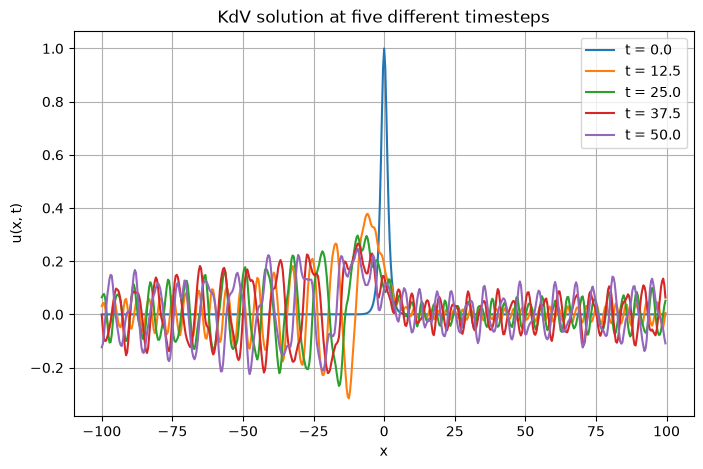

In [8]:
# Plot the solution in x for five different timesteps
indices = np.linspace(0, len(t) - 1, 5, dtype=int)

plt.figure(figsize=(8, 5))

for index in indices:
    plt.plot(x, ut.y[:, index], label=f"t = {t[index]:.1f}")

plt.xlabel("x")
plt.ylabel("u(x, t)")
plt.title("KdV solution at five different timesteps")
plt.grid(True)
plt.legend()
plt.show()
plt.show()

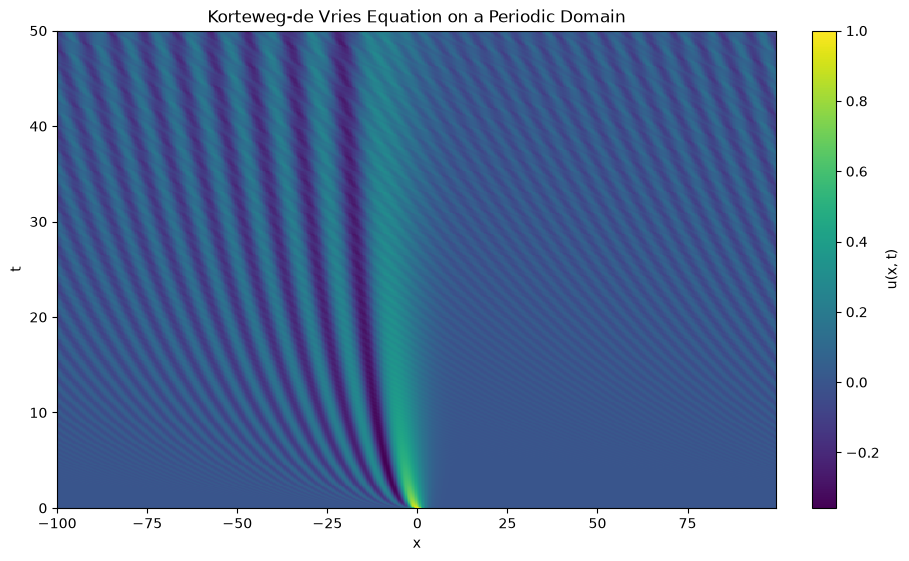

In [9]:
# Heatmap of the solution
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

plot = ax.pcolormesh(
    x,
    t,
    ut.y.T,
    shading="auto",
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_title("Korteweg-de Vries Equation on a Periodic Domain")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(t.min(), t.max())

colorbar = fig.colorbar(plot, ax=ax)
colorbar.set_label("u(x, t)")

plt.show()


Exercise 2.4

Solve the Kuramoto-Sivashinsky (KS) equation using FFT

u_t + u_x +u_xxxx + 1/2 u_x^2 = 0 with initial condition, u(x,0) = sech(x)

In [10]:
L = 200 # length of evaluation
n = 512 # number of evaluations
dx = L/n # step length
x = np.linspace(-L/2, L/2, n, endpoint=False)


kappa = 2*np.pi * np.fft.fftfreq(n, d = dx) # frequencies, ordered wavenumbers

def rhsKS(t, u, kappa):
    uhat  = np.fft.fft(u)                       # to fourier state for u
    duhat = 1j*kappa * uhat                     # to fourier state for u_x
    dddduhat = np.power((1j * kappa),4) * uhat  # to fourier state for u_xxxx
    
    ux = np.fft.ifft(duhat)                     # back to phisical state for u_x
    uxxxx = np.fft.ifft(dddduhat)               # back to phisical state for u_xxxx
    return (-ux - uxxxx - 1/2*ux**2).real       # Returns only the real part of the solution

# initial condition
u0 = 1/np.cosh(x) 

T = 200
nT = 501
t = np.linspace(0, T, nT)
t_span = (0,T)
ut = solve_ivp(rhsKS, t_span, u0, method = "BDF", t_eval = t, args = (kappa,))

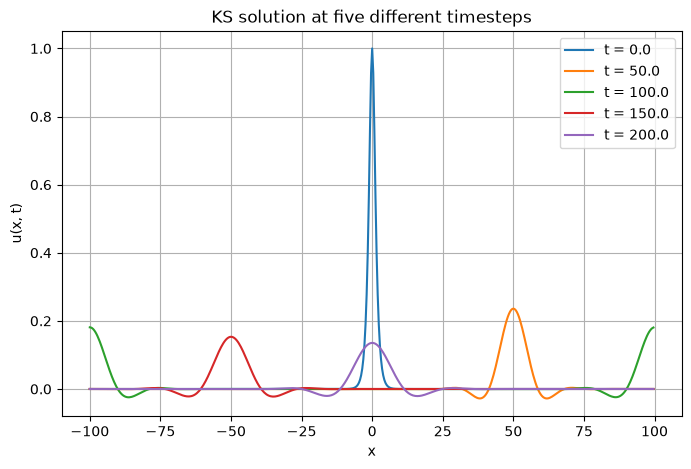

In [13]:
# Plot the solution in x for five different timesteps
indices = np.linspace(0, len(t) - 1, 5, dtype=int)

plt.figure(figsize=(8, 5))

for index in indices:
    plt.plot(x, ut.y[:, index], label=f"t = {t[index]:.1f}")

plt.xlabel("x")
plt.ylabel("u(x, t)")
plt.title("KS solution at five different timesteps")
plt.grid(True)
plt.legend()
plt.show()
plt.show()

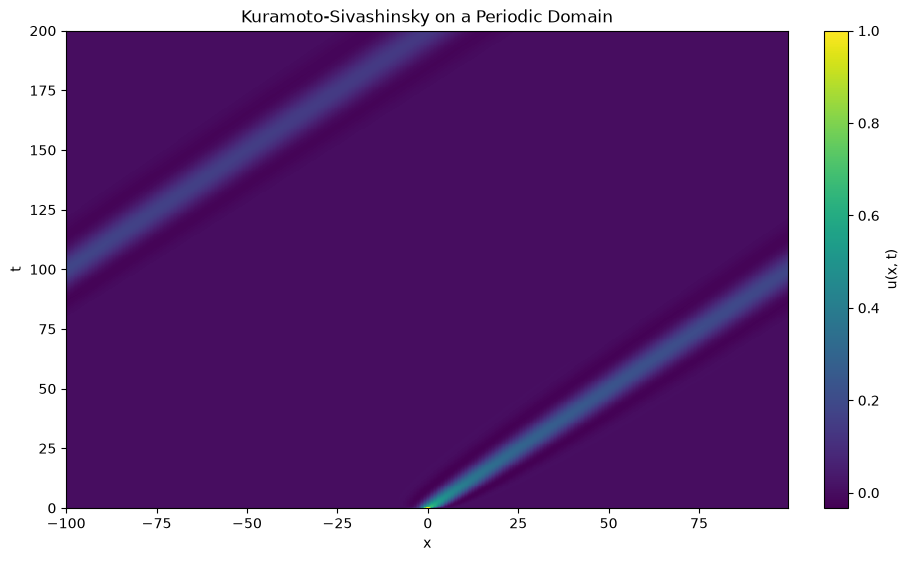

In [12]:
# Heatmap of the solution
fig, ax = plt.subplots(figsize=(9, 5.5), constrained_layout=True)

plot = ax.pcolormesh(
    x,
    t,
    ut.y.T,
    shading="auto",
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_title("Kuramoto-Sivashinsky on a Periodic Domain")
ax.set_xlim(x.min(), x.max())
ax.set_ylim(t.min(), t.max())

colorbar = fig.colorbar(plot, ax=ax)
colorbar.set_label("u(x, t)")

plt.show()